# LM · Чи точніший збіг Sentinel-2 і NASA OPERA, ніж одне джерело?

**Тип:** виміряно. **Навіщо:** Перевіряємо, чи допомагає збіг двох джерел у парку з малою кількістю рубок.

Цей ноутбук повторює блок сторінки досліджень `web/science/#lm` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('LM'))

LD · LM · LG для Греції: детекція, матчинг і розвиток вирубки в НП Дадья.

Задача      перевірити вирубку на грецькому парку й чесно показати, що можна виміряти там, де рубок мало.
Дані        Sentinel-2 L2A (AWS Earth Search): літні композити 15.06–15.09; NASA OPERA DIST-ALERT через GIBS; Hansen GFC v1.12 як лейбл; рельєф SRTM, ліс, дороги й села.
Лейбл       Hansen: втрата крон саме в році Y. Це не «рубка», а будь-яка втрата лісу.
Пожежі      це не вирубка, тому пікселі ≤ 1 км від точок FIRMS (є лише з 2021) і в контурах EFFIS + 500 м за роки Y і Y−1 відкинуті. Лишкові згарища все одно можливі.
Протокол    кілька парків: квадрати ~6 км усіх парків розкладені на фолди (вибір і тест на різних квадратах); окремо LD_transfer і LM_transfer —
            вчимося на інших парках, тест на парку, якого модель не бачила (не для вибору). З одним парком — половини парку за довготою.
  LD        вибір 2018–2021, тест 2022–2024. CI — bootstrap по блоках ~5 км.
  LM        Sentinel-2 навчається на 

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,approach,val_metric,test_metric,ci,precision,recall,true_ha,champion,diff_hist,diff_rand
0,opera,NaN,0.120,0.04–0.22,0.074,0.315,11.33,False,NaN,NaN
1,sentinel2,NaN,0.361,0.19–0.52,0.378,0.345,11.33,False,NaN,NaN
2,будь-яке,NaN,0.170,0.08–0.28,0.102,0.510,11.33,False,NaN,NaN
3,обидва,NaN,0.260,0.05–0.50,1.000,0.150,11.33,False,NaN,NaN


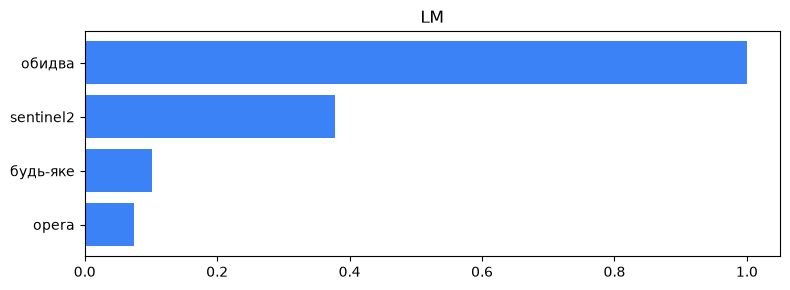

In [3]:
table, fig = report.show('LM')
table